# **Customer Segmentation Analysis Using K-Means Clustering**

## Project Overview

Customer segmentation is a data analysis technique used to divide customers into groups based on similar characteristics. Businesses use segmentation to understand customer behavior and develop targeted marketing strategies.

## Objective

The objective of this project is to group customers according to their annual income and spending scores using the K-Means clustering algorithm. The resulting segments can help businesses understand different customer groups and make informed marketing decisions.

## Dataset

This project uses the Mall Customer Segmentation dataset, which contains 200 customer records with information about customer ID, gender, age, annual income, and spending score.

## Tools and Technologies

* Python
* Pandas and NumPy
* Matplotlib and Seaborn
* Scikit-learn
* Google Colab


## 1. Importing Libraries

The libraries used in this project provide tools for data manipulation, numerical operations, visualization, and customer segmentation.

* **Pandas:** Used to load, organize, and analyze customer data.
* **NumPy:** Supports numerical computations.
* **Matplotlib:** Used to create graphs and charts.
* **Seaborn:** Helps create statistical visualizations.

These libraries provide the foundation for analyzing the dataset and identifying customer groups.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Loading the Dataset

The Mall Customer Segmentation dataset is used to analyze customer characteristics and identify groups with similar spending behavior.

The dataset contains 200 customer records and five columns: CustomerID, Gender, Age, Annual Income (k$), and Spending Score (1-100).

The dataset is loaded into a Pandas DataFrame, which makes it easier to inspect, clean, and analyze the data.


In [4]:
import pandas as pd

df = pd.read_csv('/content/Mall_Customers.csv')

print("Dataset loaded successfully!")

Dataset loaded successfully!


## 3. Initial Data Inspection

After loading the dataset, we inspect its structure and check the quality of the available data.

The following operations are performed:

* **Dataset Shape (`df.shape`):** Identifies the number of rows and columns in the dataset.
* **Column Names (`df.columns`):** Displays the names of all available variables.
* **Data Types and Information (`df.info()`):** Provides information about column data types and non-null values.
* **Missing Values (`df.isnull().sum()`):** Checks whether any columns contain missing values.

These checks help us understand the dataset and determine whether any data-cleaning steps are necessary before performing further analysis.


In [5]:
print("Dataset shape:", df.shape)

Dataset shape: (200, 5)


In [6]:
print(df.columns)

Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='object')


## 4. Data Cleaning

Data cleaning helps ensure that the dataset is suitable for analysis and clustering.

The following checks are performed:

* **Missing Values:** We check whether any values are missing from the dataset.
* **Duplicate Records:** We identify duplicate rows that could affect the analysis.
* **Data Quality:** We review the dataset to determine whether any cleaning is required.

The dataset is checked before proceeding with feature selection and clustering. Any necessary cleaning should be performed only if issues are identified.


In [7]:
print(df.isnull().sum())

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


## 5. Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand the dataset, identify patterns, and examine relationships between customer characteristics before applying a clustering algorithm.

### Statistical Analysis

The `df.describe()` function provides summary statistics, including the mean, standard deviation, minimum, maximum, and quartiles of numerical columns.

### Data Visualization

The following visualizations are used to explore customer characteristics:

* **Age Distribution:** Examines the distribution of customer ages.
* **Annual Income Distribution:** Shows how annual income varies among customers.
* **Spending Score Distribution:** Helps us understand the distribution of customer spending scores.
* **Income vs. Spending Score:** Displays the relationship between annual income and spending score, with customers distinguished by gender.

These visualizations help us understand customer characteristics and prepare for the segmentation process.


In [9]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


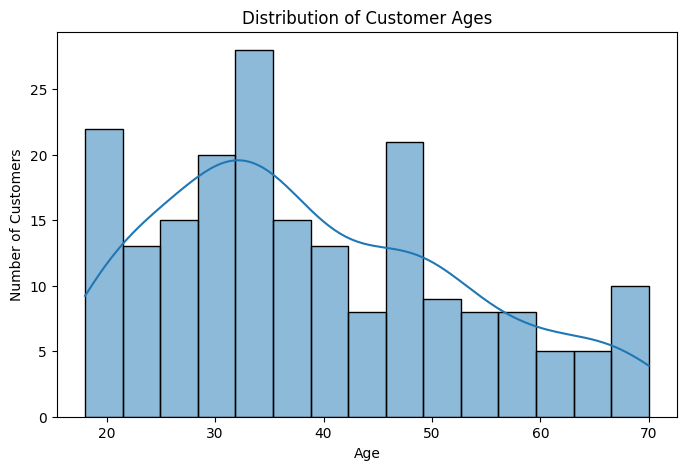

In [10]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='Age', bins=15, kde=True)

plt.title('Distribution of Customer Ages')
plt.xlabel('Age')
plt.ylabel('Number of Customers')

plt.show()

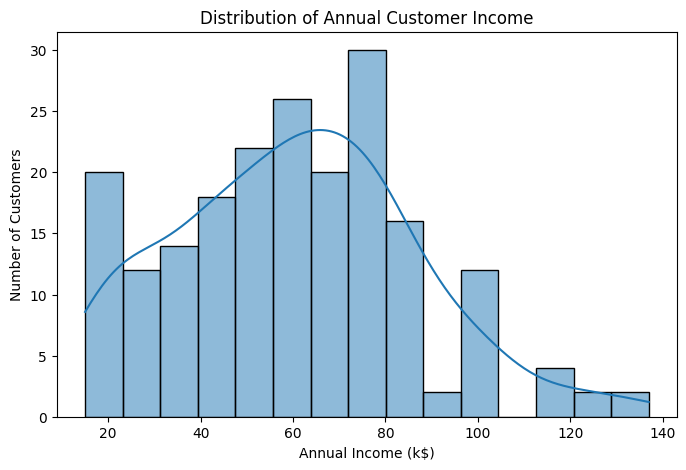

In [11]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='Annual Income (k$)', bins=15, kde=True)

plt.title('Distribution of Annual Customer Income')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Number of Customers')

plt.show()

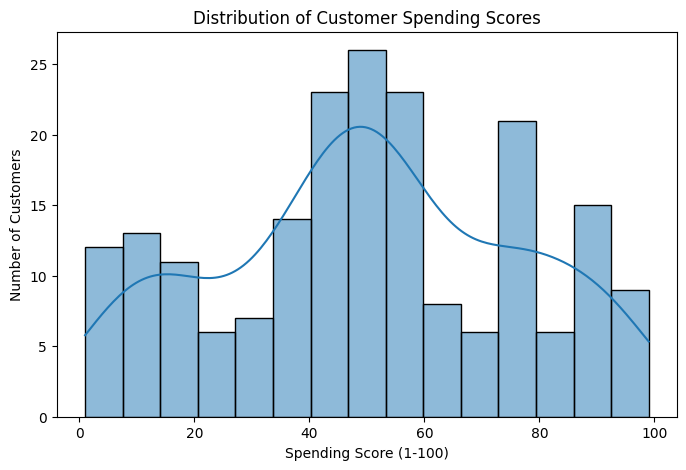

In [12]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='Spending Score (1-100)', bins=15, kde=True)

plt.title('Distribution of Customer Spending Scores')
plt.xlabel('Spending Score (1-100)')
plt.ylabel('Number of Customers')

plt.show()

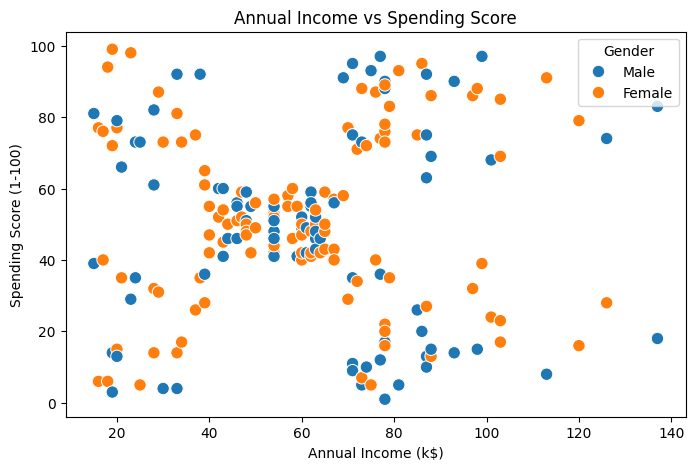

In [13]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Gender',
    s=80
)

plt.title('Annual Income vs Spending Score')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')

plt.show()

## 6. Feature Selection

Feature selection involves choosing the most relevant variables for the clustering process.

In this project, we select two features:

* **Annual Income (k$):** Represents the customer's annual income in thousands of dollars.
* **Spending Score (1-100):** Represents the customer's spending score on a scale from 1 to 100.

These features help us examine how customers with different income levels behave in terms of spending.

The selected features are stored in a separate DataFrame named `X`, which is used as input for the K-Means clustering algorithm.

CustomerID, Gender, and Age are not included in the clustering model because this analysis focuses specifically on the relationship between annual income and spending score.


In [14]:
# Select features for customer segmentation
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

# Display the first five rows
X.head()

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


## 7. Feature Scaling

Feature scaling transforms numerical features to a comparable scale before clustering.

In this project, `StandardScaler` is used to standardize Annual Income and Spending Score. Standardization transforms each feature to have a mean approximately equal to 0 and a standard deviation approximately equal to 1.

Scaling is important because K-Means uses distances to determine which customers are similar. Without scaling, a feature with a larger numerical range could have a greater influence on the clustering results.

The standardized data is stored in `X_scaled` and is used for the Elbow Method and K-Means clustering.


In [15]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Data standardized successfully!")
print("Scaled data shape:", X_scaled.shape)

Data standardized successfully!
Scaled data shape: (200, 2)


## 8. Finding the Optimal Number of Clusters — Elbow Method

The Elbow Method is used to estimate the appropriate number of clusters for the K-Means algorithm.

In this method, K-Means is evaluated for different values of `k`, and the Within-Cluster Sum of Squares (WCSS) is calculated for each value.

WCSS measures how close the data points are to their assigned cluster centers. As the number of clusters increases, WCSS generally decreases.

The results are plotted on a graph, with the number of clusters on the x-axis and WCSS on the y-axis. The point where the decrease in WCSS begins to slow down is known as the elbow.

Based on the Elbow Method analysis, five clusters were selected for this project.


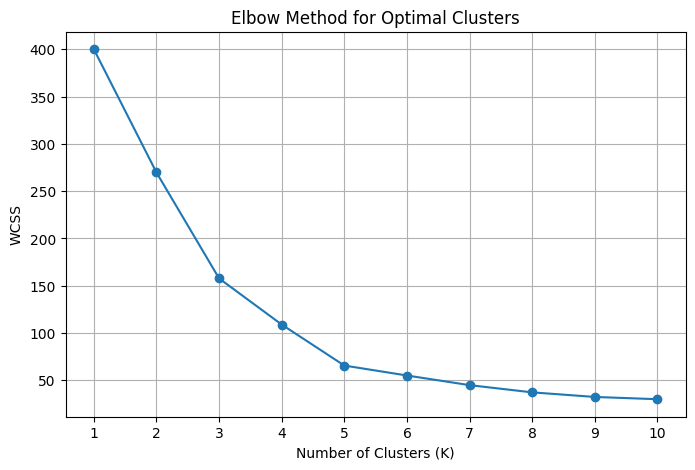

In [16]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

wcss = []

for i in range(1, 11):
    kmeans = KMeans(
        n_clusters=i,
        init='k-means++',
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')

plt.title('Elbow Method for Optimal Clusters')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.xticks(range(1, 11))
plt.grid(True)

plt.show()

## 9. Building the K-Means Clustering Model

K-Means is an unsupervised machine learning algorithm that groups data points into clusters based on their similarity.

In this project, the algorithm is configured to create five customer clusters using the standardized Annual Income and Spending Score features.

The model works by:

1. Initializing five cluster centers.
2. Assigning each customer to the nearest cluster center.
3. Updating the cluster centers based on the assigned customers.
4. Repeating the assignment and update process until the clusters stabilize.

The `random_state=42` parameter helps make the results reproducible, while `n_init=10` allows the algorithm to run with multiple initializations.

Finally, the assigned cluster labels are stored in a new `Cluster` column in the original DataFrame.


In [17]:
# Build the K-Means clustering model
kmeans = KMeans(
    n_clusters=5,
    init='k-means++',
    random_state=42,
    n_init=10
)

# Train the model
kmeans.fit(X_scaled)

# Assign a cluster to each customer
df['Cluster'] = kmeans.labels_

print("K-Means model trained successfully!")
print("\nCustomers assigned to clusters:")
print(df[['Annual Income (k$)', 'Spending Score (1-100)', 'Cluster']].head(10))

K-Means model trained successfully!

Customers assigned to clusters:
   Annual Income (k$)  Spending Score (1-100)  Cluster
0                  15                      39        4
1                  15                      81        2
2                  16                       6        4
3                  16                      77        2
4                  17                      40        4
5                  17                      76        2
6                  18                       6        4
7                  18                      94        2
8                  19                       3        4
9                  19                      72        2


## 10. Visualizing Customer Segments

After training the K-Means model, we visualize the resulting customer groups using a scatter plot.

* **X-axis:** Annual Income (k$).
* **Y-axis:** Spending Score (1-100).
* **Different colors:** Represent the five clusters identified by the algorithm.
* **Cluster centers:** Represent the central points of the identified groups.

This visualization helps us compare customers based on their income and spending behavior and observe how the algorithm separates them into different segments.

The plot provides a visual overview of customer segmentation and helps identify patterns that may be useful for business decision-making.


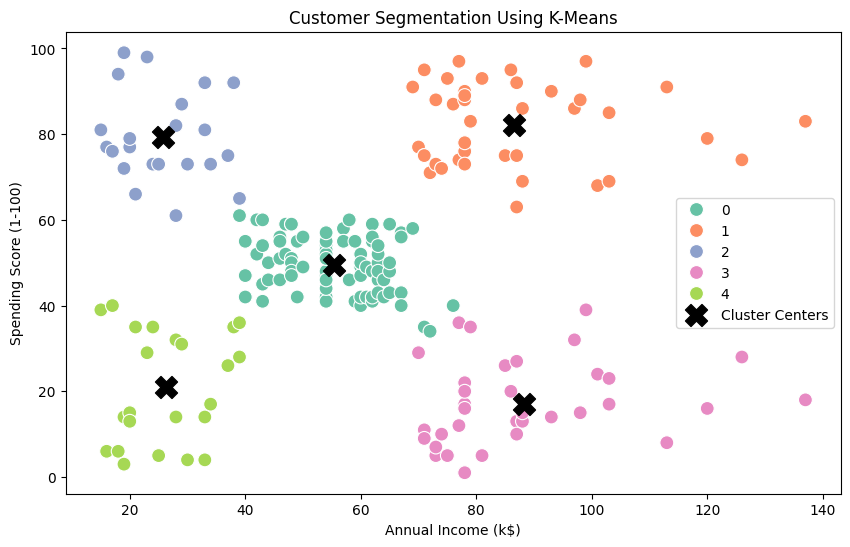

In [18]:
# Visualize the customer clusters
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Cluster',
    palette='Set2',
    s=100
)

# Plot the cluster centers in the original feature scale
centers = scaler.inverse_transform(kmeans.cluster_centers_)

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    s=250,
    marker='X',
    color='black',
    label='Cluster Centers'
)

plt.title('Customer Segmentation Using K-Means')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()
plt.show()

## 11. Customer Segment Analysis

After assigning customers to clusters, we calculate the average annual income and spending score for each group.

These averages help us understand the characteristics of the customers within each segment.

The analysis focuses on five customer groups:

* **Cluster 0:** Customers with moderate income and moderate spending.
* **Cluster 1:** Customers with high income and high spending.
* **Cluster 2:** Customers with lower income and high spending.
* **Cluster 3:** Customers with high income and low spending.
* **Cluster 4:** Customers with lower income and low spending.

Understanding these groups can help businesses develop targeted marketing strategies, personalize promotions, and improve customer engagement.

These interpretations are based on the average values of annual income and spending score for each cluster.


In [19]:
# Analyze the average characteristics of each cluster
cluster_summary = df.groupby('Cluster')[
    ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
].mean().round(2)

print("Customer Segment Analysis:")
display(cluster_summary)

Customer Segment Analysis:


,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
0,42.72,55.30,49.52
1,32.69,86.54,82.13
2,25.27,25.73,79.36
3,41.11,88.20,17.11
4,45.22,26.30,20.91


## 12. Customer Cluster Distribution

After clustering, we count the number of customers assigned to each group.

This analysis helps us understand the size of each customer segment and compare how customers are distributed across the five clusters.

The cluster distribution can help businesses identify larger customer groups and determine where targeted marketing campaigns may be useful.

The number of customers in each cluster is calculated using the `value_counts()` function.


In [20]:
# Count customers in each cluster
cluster_counts = df['Cluster'].value_counts().sort_index()

print("Number of customers in each cluster:")
print(cluster_counts)

Number of customers in each cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


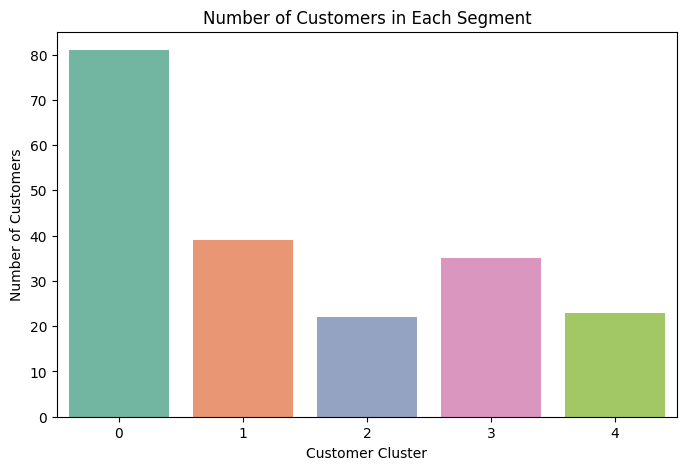

In [21]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Cluster', hue='Cluster', palette='Set2', legend=False)

plt.title('Number of Customers in Each Segment')
plt.xlabel('Customer Cluster')
plt.ylabel('Number of Customers')

plt.show()

## 13. Model Evaluation Using Silhouette Score

The silhouette score is used to evaluate the quality of clustering by measuring how well each data point fits within its assigned cluster compared with other clusters.

The score ranges from -1 to +1:

* **Close to +1:** Data points are generally well matched to their own clusters and separated from other clusters.
* **Around 0:** Some clusters may overlap.
* **Below 0:** Some data points may be assigned to less suitable clusters.

The K-Means model achieved a silhouette score of **0.555**. This indicates a reasonably good separation of customer groups, although some overlap may remain.

The score helps assess the clustering results but does not, by itself, prove that five clusters is the optimal choice.


In [22]:
from sklearn.metrics import silhouette_score

score = silhouette_score(X_scaled, df['Cluster'])

print("Silhouette Score:", round(score, 3))

Silhouette Score: 0.555


In [23]:
df.to_csv('Customer_Segmentation_Results.csv', index=False)

print("Results saved successfully!")

Results saved successfully!


In [24]:
from google.colab import files

files.download('Customer_Segmentation_Results.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# 14. Conclusion

In this project, K-Means clustering was used to segment customers based on their annual income and spending scores. The Mall Customer Segmentation dataset, containing 200 customer records, was analyzed using Python and its data science libraries.

The Elbow Method was used to help select five clusters. The customer groups were visualized using scatter plots, and their average income and spending scores were analyzed to understand their characteristics.

The model achieved a silhouette score of 0.555, indicating reasonably good separation between the identified customer groups, although some overlap may remain.

### Key Findings

* Customers can be grouped into five segments based on annual income and spending score.
* The clusters reveal different combinations of income and spending behavior.
* These segments can help businesses develop targeted marketing campaigns and personalized offers.

### Future Improvements

* Compare silhouette scores for different numbers of clusters.
* Explore additional customer features, such as age and gender.
* Evaluate whether alternative clustering algorithms provide better results.
* Develop an interactive dashboard to present customer segments.

Overall, this project demonstrates how unsupervised machine learning can help businesses understand customer groups and make more informed marketing decisions.
